In [1]:
import os
os.chdir("/Users/eloelo/Projects/plant-disease-detection")

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("Working from:", os.getcwd())

TensorFlow: 2.19.1
Working from: /Users/eloelo/Projects/plant-disease-detection


In [2]:
image_size = (224, 224)
batch_size = 32

train_data = tf.data.Dataset.load("data/splits_tfds/train")
val_data = tf.data.Dataset.load("data/splits_tfds/val")
test_data = tf.data.Dataset.load("data/splits_tfds/test")

def resize_image(image, label):
    image = tf.image.resize(image, image_size)
    return image, label

train_data = train_data.shuffle(14522, seed=42)

train_data = train_data.map(resize_image).batch(batch_size)
val_data = val_data.map(resize_image).batch(batch_size)
test_data = test_data.map(resize_image).batch(batch_size)

class_names = [
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___healthy",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_mosaic_virus",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
]

print("Train batches:", len(train_data))
print("Val batches:", len(val_data))
print("Test batches:", len(test_data))

Train batches: 454
Val batches: 57
Test batches: 58


2026-09-27 20:37:05.469829: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Pro
2026-09-27 20:37:05.469850: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-09-27 20:37:05.469855: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
I0000 00:00:1790521625.470173  198231 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1790521625.470310  198231 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [3]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

def augment(image, label):
    image = data_augmentation(image, training=True)
    return image, label

train_aug = train_data.map(augment).prefetch(tf.data.AUTOTUNE)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    min_delta=0.001,
    restore_best_weights=True,
    verbose=1,
)

lr_on_plateau = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.1,
    patience=3,
    min_lr=1e-7,
    verbose=1,
)

print("Augmentation and callbacks ready")

Augmentation and callbacks ready


In [4]:
base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
)

base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = layers.Rescaling(1./127.5, offset=-1)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(10, activation="softmax")(x)

mobilenet_model = keras.Model(inputs, outputs)

mobilenet_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [5]:
mobilenet_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

mobilenet_history = mobilenet_model.fit(
    train_aug,
    validation_data=val_data,
    epochs=30,
    callbacks=[early_stopping, lr_on_plateau],
)

Epoch 1/30


/opt/anaconda3/envs/plant/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-09-27 20:37:06.524132: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


454/454 ━━━━━━━━━━━━━━━━━━━━ 41s 83ms/step - accuracy: 0.7505 - loss: 0.7696 - val_accuracy: 0.8455 - val_loss: 0.4871 - learning_rate: 0.0010
Epoch 2/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 38s 80ms/step - accuracy: 0.8536 - loss: 0.4493 - val_accuracy: 0.8731 - val_loss: 0.4054 - learning_rate: 0.0010
Epoch 3/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 38s 80ms/step - accuracy: 0.8718 - loss: 0.3903 - val_accuracy: 0.8902 - val_loss: 0.3404 - learning_rate: 0.0010
Epoch 4/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 39s 84ms/step - accuracy: 0.8836 - loss: 0.3507 - val_accuracy: 0.8896 - val_loss: 0.3257 - learning_rate: 0.0010
Epoch 5/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 40s 84ms/step - accuracy: 0.8869 - loss: 0.3314 - val_accuracy: 0.8968 - val_loss: 0.3081 - learning_rate: 0.0010
Epoch 6/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 38s 81ms/step - accuracy: 0.8947 - loss: 0.3141 - val_accuracy: 0.9073 - val_loss: 0.2864 - learning_rate: 0.0010
Epoch 7/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 38s 80ms/step - accuracy: 0.8949 - loss: 0.3097

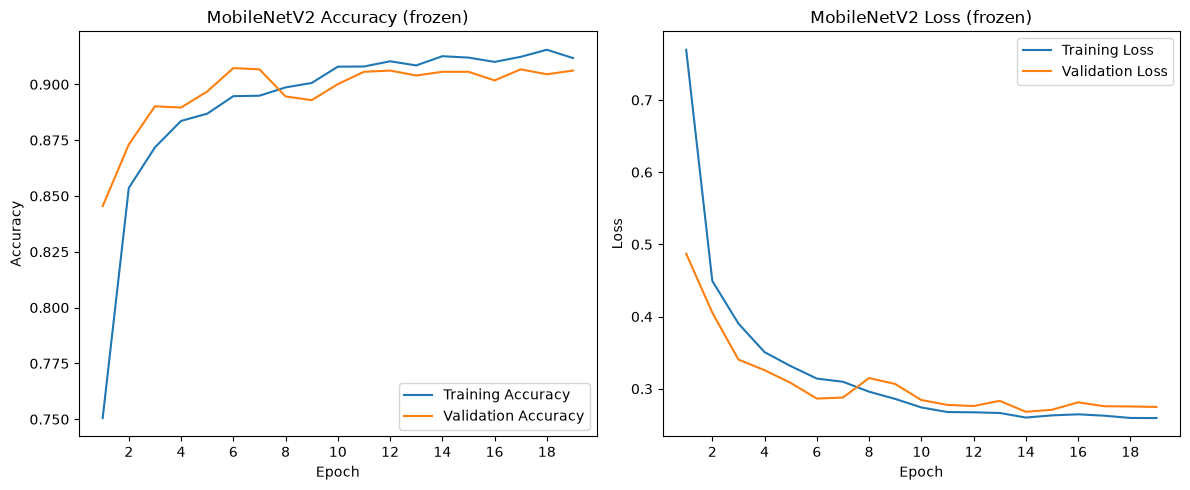

In [6]:
epochs_range = list(range(1, len(mobilenet_history.history["loss"]) + 1))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, mobilenet_history.history["accuracy"], label="Training Accuracy")
plt.plot(epochs_range, mobilenet_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MobileNetV2 Accuracy (frozen)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.xticks(range(2, len(epochs_range) + 1, 2))

plt.subplot(1, 2, 2)
plt.plot(epochs_range, mobilenet_history.history["loss"], label="Training Loss")
plt.plot(epochs_range, mobilenet_history.history["val_loss"], label="Validation Loss")
plt.title("MobileNetV2 Loss (frozen)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks(range(2, len(epochs_range) + 1, 2))

plt.tight_layout()
plt.savefig("reports/figures/mobilenet_curves.png", dpi=150)
plt.show()

In [7]:
mobilenet_model.save("models/mobilenet_frozen.keras")
print("Model saved")

Model saved


### MobileNetV2: Frozen
- ImageNet MobileNetV2, frozen, only the last layer trained (12.8K params)
- Train images augmented (flip, rotate, zoom, contrast); val and test left as they are
- LR 0.001, with EarlyStopping and ReduceLROnPlateau
- Stopped at epoch 19, best epoch 14: val acc 90.6%, val loss 0.27
- Dropout 0.2 before the last layer (regularisation)
- The earlier run without augmentation got 92.7%, but it also had 10 fixed epochs and no callbacks, so augmentation is the main difference but not the only one
- Train and val about the same (91.3% vs 90.6%), no overfitting

In [8]:
mobilenet_model = keras.models.load_model("models/mobilenet_frozen.keras")
base_model = mobilenet_model.get_layer("mobilenetv2_1.00_224")

base_model.trainable = True

for layer in base_model.layers[:100]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

mobilenet_model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("MobileNetV2 layers:", len(base_model.layers))
mobilenet_model.summary()

MobileNetV2 layers: 154


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 1,852,426 (7.07 MB)

 Non-trainable params: 418,368 (1.60 MB)

In [9]:
frozen_epochs = len(mobilenet_history.history["loss"])

fine_tune_history = mobilenet_model.fit(
    train_aug,
    validation_data=val_data,
    epochs=frozen_epochs + 20,
    initial_epoch=frozen_epochs,
    callbacks=[early_stopping, lr_on_plateau],
)

Epoch 20/39
454/454 ━━━━━━━━━━━━━━━━━━━━ 42s 84ms/step - accuracy: 0.9114 - loss: 0.2573 - val_accuracy: 0.9200 - val_loss: 0.2359 - learning_rate: 1.0000e-05
Epoch 21/39
454/454 ━━━━━━━━━━━━━━━━━━━━ 38s 79ms/step - accuracy: 0.9377 - loss: 0.1899 - val_accuracy: 0.9272 - val_loss: 0.2192 - learning_rate: 1.0000e-05
Epoch 22/39
454/454 ━━━━━━━━━━━━━━━━━━━━ 38s 80ms/step - accuracy: 0.9420 - loss: 0.1734 - val_accuracy: 0.9327 - val_loss: 0.1907 - learning_rate: 1.0000e-05
Epoch 23/39
454/454 ━━━━━━━━━━━━━━━━━━━━ 38s 80ms/step - accuracy: 0.9514 - loss: 0.1442 - val_accuracy: 0.9238 - val_loss: 0.2344 - learning_rate: 1.0000e-05
Epoch 24/39
454/454 ━━━━━━━━━━━━━━━━━━━━ 38s 79ms/step - accuracy: 0.9550 - loss: 0.1309 - val_accuracy: 0.9327 - val_loss: 0.1948 - learning_rate: 1.0000e-05
Epoch 25/39
454/454 ━━━━━━━━━━━━━━━━━━━━ 38s 80ms/step - accuracy: 0.9577 - loss: 0.1186 - val_accuracy: 0.9393 - val_loss: 0.1751 - learning_rate: 1.0000e-05
Epoch 26/39
454/454 ━━━━━━━━━━━━━━━━━━━━ 38s 8

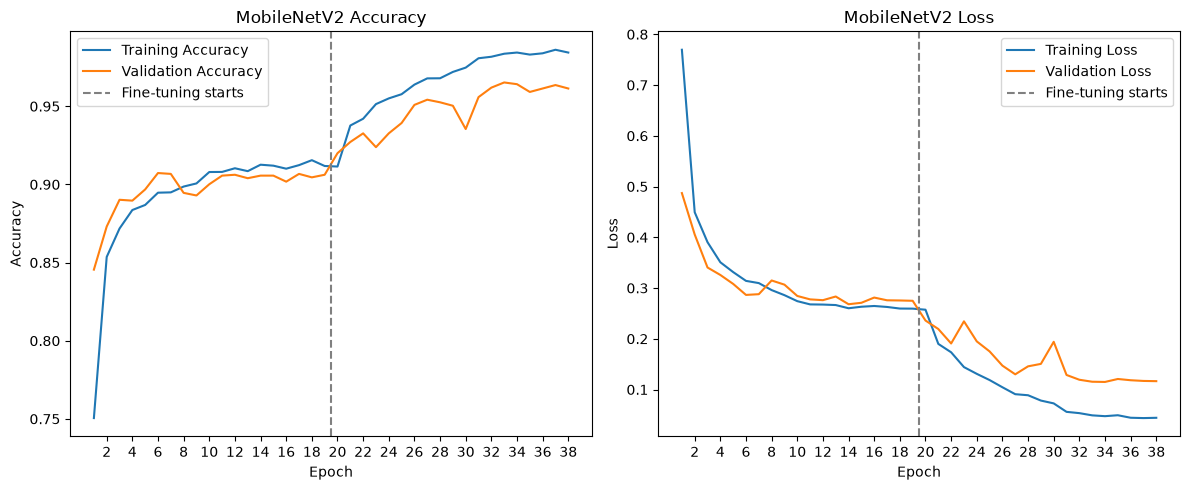

In [10]:
accuracy = mobilenet_history.history["accuracy"] + fine_tune_history.history["accuracy"]
val_accuracy = mobilenet_history.history["val_accuracy"] + fine_tune_history.history["val_accuracy"]
loss = mobilenet_history.history["loss"] + fine_tune_history.history["loss"]
val_loss = mobilenet_history.history["val_loss"] + fine_tune_history.history["val_loss"]

epochs_range = list(range(1, len(accuracy) + 1))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, accuracy, label="Training Accuracy")
plt.plot(epochs_range, val_accuracy, label="Validation Accuracy")
plt.axvline(x=frozen_epochs + 0.5, color="gray", linestyle="--", label="Fine-tuning starts")
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.xticks(range(2, len(accuracy) + 1, 2))

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.axvline(x=frozen_epochs + 0.5, color="gray", linestyle="--", label="Fine-tuning starts")
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks(range(2, len(accuracy) + 1, 2))

plt.tight_layout()
plt.savefig("reports/figures/mobilenet_finetune_curves.png", dpi=150)
plt.show()

In [11]:
mobilenet_model.save("models/mobilenet_finetuned.keras")
print("Model saved")

Model saved


### MobileNetV2: Fine-Tuning
- Loaded the saved frozen model, unfroze layers 100–153, kept BatchNorm frozen
- LR 0.00001, trainable params 1.85M
- First try without freezing BatchNorm broke training (train acc fell to 75%), so the freeze is needed
- Stopped at epoch 38, best epoch 33: val acc 96.5%, val loss 0.12
- The earlier run without augmentation also reached 96.5%, with a bigger train–val gap (2.8 vs 1.9 points); that run also had no callbacks

In [12]:
keras.utils.set_random_seed(42)

resnet_preprocess = keras.applications.resnet50.preprocess_input

def prepare_for_resnet(image, label):
    image = resnet_preprocess(image)
    return image, label

resnet_train = train_aug.map(prepare_for_resnet).prefetch(tf.data.AUTOTUNE)
resnet_val = val_data.map(prepare_for_resnet)
resnet_test = test_data.map(prepare_for_resnet)

resnet_base = keras.applications.ResNet50(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
)

resnet_base.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = resnet_base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(10, activation="softmax")(x)

resnet_model = keras.Model(inputs, outputs)

resnet_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        20,490 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,608,202 (90.06 MB)

 Trainable params: 20,490 (80.04 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [13]:
resnet_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

resnet_history = resnet_model.fit(
    resnet_train,
    validation_data=resnet_val,
    epochs=30,
    callbacks=[early_stopping, lr_on_plateau],
)

Epoch 1/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 57s 117ms/step - accuracy: 0.8215 - loss: 0.5710 - val_accuracy: 0.8692 - val_loss: 0.3661 - learning_rate: 0.0010
Epoch 2/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 52s 111ms/step - accuracy: 0.9260 - loss: 0.2508 - val_accuracy: 0.8929 - val_loss: 0.3320 - learning_rate: 0.0010
Epoch 3/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 52s 111ms/step - accuracy: 0.9393 - loss: 0.1971 - val_accuracy: 0.9073 - val_loss: 0.2568 - learning_rate: 0.0010
Epoch 4/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 51s 109ms/step - accuracy: 0.9469 - loss: 0.1679 - val_accuracy: 0.9029 - val_loss: 0.2727 - learning_rate: 0.0010
Epoch 5/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 51s 110ms/step - accuracy: 0.9523 - loss: 0.1492 - val_accuracy: 0.9128 - val_loss: 0.2326 - learning_rate: 0.0010
Epoch 6/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 52s 110ms/step - accuracy: 0.9576 - loss: 0.1345 - val_accuracy: 0.9216 - val_loss: 0.2096 - learning_rate: 0.0010
Epoch 7/30
454/454 ━━━━━━━━━━━━━━━━━━━━ 51s 110ms/step - accuracy: 0.9

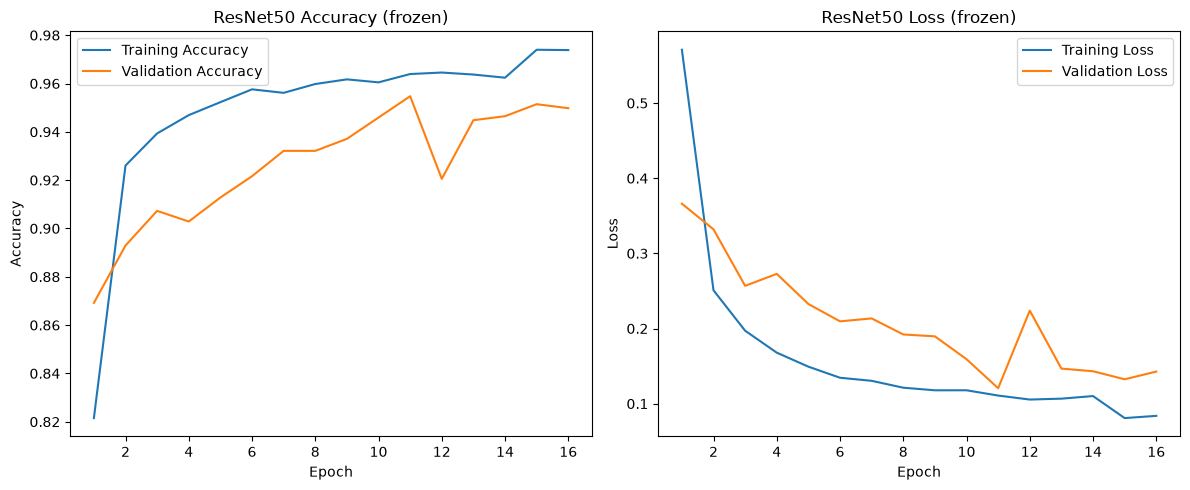

Model saved


In [14]:
epochs_range = list(range(1, len(resnet_history.history["loss"]) + 1))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, resnet_history.history["accuracy"], label="Training Accuracy")
plt.plot(epochs_range, resnet_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ResNet50 Accuracy (frozen)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.xticks(range(2, len(epochs_range) + 1, 2))

plt.subplot(1, 2, 2)
plt.plot(epochs_range, resnet_history.history["loss"], label="Training Loss")
plt.plot(epochs_range, resnet_history.history["val_loss"], label="Validation Loss")
plt.title("ResNet50 Loss (frozen)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks(range(2, len(epochs_range) + 1, 2))

plt.tight_layout()
plt.savefig("reports/figures/resnet_frozen_curves.png", dpi=150)
plt.show()

resnet_model.save("models/resnet_frozen.keras")
print("Model saved")

### ResNet50: Frozen
- Same setup as MobileNetV2 frozen, with ResNet50 as the base
- preprocess_input applied to the data after augmentation
- Trainable params: 20.5K
- Stopped at epoch 16, best epoch 11: val acc 95.5%, val loss 0.12
- The earlier run without augmentation got 98.0% (10 fixed epochs, no callbacks)
- Not fine-tuned: MobileNetV2 fine-tuned was already better on val (96.5% vs 95.5%) and 10 times smaller, so only MobileNetV2 was fine-tuned
- About 1.3 times slower per epoch (about 51s vs 38s) and 10 times bigger than MobileNetV2 (23.6M vs 2.3M parameters)

### Experiment log (validation set)

| # | Model | Setup | Best val acc | Val loss | Notes |
|---|---|---|---|---|---|
| 1 | Baseline CNN | LR 0.001 | — | >300 | Loss exploded |
| 2 | Baseline CNN | LR 0.0001, 10 epochs, no seed | 72% / 82% | — | Two runs, big difference, so seed fixed |
| 3 | Baseline CNN | LR 0.0001, 10 epochs, seed 42 | 88.5% | 0.36 | |
| 4 | Baseline CNN | + EarlyStopping, ReduceLROnPlateau | 90.2% | 0.30 | Final baseline |
| 5 | MobileNetV2 frozen | No augmentation, 10 epochs | 92.7% | 0.23 | |
| 6 | MobileNetV2 fine-tuned | No augmentation, 10 + 10 epochs | 96.5% | 0.10 | |
| 7 | ResNet50 frozen | No augmentation, 10 epochs | 98.0% | 0.07 | |
| 8 | MobileNetV2 frozen | Augmentation + callbacks | 90.6% | 0.27 | Final frozen |
| 9 | MobileNetV2 fine-tuned | BatchNorm not frozen | 91.3% | 0.26 | Training broke, discarded |
| 10 | MobileNetV2 fine-tuned | Augmentation + callbacks, BatchNorm frozen | 96.5% | 0.12 | **Chosen model** |
| 11 | ResNet50 frozen | Augmentation + callbacks | 95.5% | 0.12 | Final ResNet50 |

- Fixed in every run: image 224 x 224, batch size 32, Adam, seed 42 (from run 3), Dropout 0.2 in the transfer models
- Tuned: learning rate, number of epochs (through callbacks), fine-tuned layers (100–153), augmentation on or off
- Chosen: run 10, the best val accuracy among the final runs, and the smallest model
- Test results for the final runs (4, 8, 10, 11) are in notebook 04